In [9]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ lubridate 1.9.4     ✔ tibble    3.2.1
✔ purrr     1.0.2     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# Part A – Data Preparation and Descriptive Analysis

### A1

In [2]:
whr <- read.csv("/kaggle/input/datasets/ajaypalsinghlo/world-happiness-report-2021/world-happiness-report-2021.csv", check.names = FALSE)
names(whr) 

vars <- c("Ladder score", "Logged GDP per capita", "Social support",
          "Healthy life expectancy", "Freedom to make life choices",
          "Generosity", "Perceptions of corruption")

dat <- na.omit(whr[, vars])
cat("Observations:", nrow(dat), " Variables:", ncol(dat), "\n")


[1] "Country name"                              
 [2] "Regional indicator"                        
 [3] "Ladder score"                              
 [4] "Standard error of ladder score"            
 [5] "upperwhisker"                              
 [6] "lowerwhisker"                              
 [7] "Logged GDP per capita"                     
 [8] "Social support"                            
 [9] "Healthy life expectancy"                   
[10] "Freedom to make life choices"              
[11] "Generosity"                                
[12] "Perceptions of corruption"                 
[13] "Ladder score in Dystopia"                  
[14] "Explained by: Log GDP per capita"          
[15] "Explained by: Social support"              
[16] "Explained by: Healthy life expectancy"     
[17] "Explained by: Freedom to make life choices"
[18] "Explained by: Generosity"                  
[19] "Explained by: Perceptions of corruption"   
[20] "Dystopia + residual"

Observations: 149  Variables: 7 


### A2

In [3]:
desc <- data.frame(Mean = sapply(dat, mean), SD = sapply(dat, sd))
print(round(desc, 3))

                               Mean    SD
Ladder score                  5.533 1.074
Logged GDP per capita         9.432 1.159
Social support                0.815 0.115
Healthy life expectancy      64.993 6.762
Freedom to make life choices  0.792 0.113
Generosity                   -0.015 0.151
Perceptions of corruption     0.727 0.179


### A3

PCA finds the directions of maximum variance. If the raw variables were used, Healthy life expectancy (SD 6.762) would dominate the first component simply because its numbers are larger, not because it is more important. Standardizing gives every variable a mean of 0 and an SD of 1, so each contributes equally to the total variance. It also makes the covariance matrix of the standardized data equal to the correlation matrix, which is the basis required for this PCA.

### A4

In [4]:
cor_mat <- cor(dat)
print(round(cor_mat, 3))

idx <- which(upper.tri(cor_mat), arr.ind = TRUE)
pairs <- data.frame(Var1 = rownames(cor_mat)[idx[, 1]],
                    Var2 = colnames(cor_mat)[idx[, 2]],
                    r = cor_mat[idx])
print(head(pairs[order(-abs(pairs$r)), ], 5), digits = 3)

                             Ladder score Logged GDP per capita Social support
Ladder score                        1.000                 0.790          0.757
Logged GDP per capita               0.790                 1.000          0.785
Social support                      0.757                 0.785          1.000
Healthy life expectancy             0.768                 0.859          0.723
Freedom to make life choices        0.608                 0.432          0.483
Generosity                         -0.018                -0.199         -0.115
Perceptions of corruption          -0.421                -0.342         -0.203
                             Healthy life expectancy
Ladder score                                   0.768
Logged GDP per capita                          0.859
Social support                                 0.723
Healthy life expectancy                        1.000
Freedom to make life choices                   0.461
Generosity                                    -0.1

Ladder score, Logged GDP per capita, Social support and Healthy life expectancy are strongly and positively correlated with one another. The strongest pairs are:

Logged GDP per capita and Healthy life expectancy (r = 0.859): wealthier countries tend to have longer healthy lives.
Ladder score and Logged GDP per capita (r = 0.790): wealthier countries report higher life evaluations.
Also notable: Logged GDP and Social support (0.785), Ladder score and Healthy life expectancy (0.768), and Ladder score and Social support (0.757).

The strongest negative relationship is Ladder score and Perceptions of corruption (r = -0.421). Perceptions of corruption is also negatively related to Freedom to make life choices (-0.401) and Healthy life expectancy (-0.364). Generosity is weakly related to almost everything (|r| ≤ 0.199), so it carries information that is mostly separate from the other six variables. Overall, the many sizable correlations show there is redundancy, which supports using PCA for data reduction.

# Part B – Principal Component Analysis

### B1

In [6]:
pca <- prcomp(dat, center = TRUE, scale. = TRUE)
pca

Standard deviations (1, .., p=7):
[1] 1.9782586 1.1354604 0.8415559 0.7200330 0.5009840 0.4397610 0.3552241

Rotation (n x k) = (7 x 7):
                                     PC1         PC2          PC3         PC4
Ladder score                 -0.46405323  0.03959557 -0.087526524  0.01320109
Logged GDP per capita        -0.45911839 -0.19661846  0.002088655  0.25605783
Social support               -0.43251174 -0.16257908 -0.323613245  0.08672118
Healthy life expectancy      -0.45302793 -0.14588528  0.032456957  0.23001752
Freedom to make life choices -0.34067869  0.36458144 -0.167217111 -0.81105400
Generosity                    0.04243769  0.75341860 -0.466264426  0.44934871
Perceptions of corruption     0.25239109 -0.45989095 -0.800744454 -0.11877984
                                     PC5         PC6         PC7
Ladder score                  0.09541532  0.86896001  0.10514776
Logged GDP per capita        -0.17375075 -0.12406829 -0.79962444
Social support                0.70437478 -0.

### B2 - B4

In [7]:
eig  <- pca$sdev^2
prop <- eig / sum(eig)
cum  <- cumsum(prop)
var_table <- data.frame(PC = paste0("PC", 1:7), Eigenvalue = eig,
                        Proportion = prop, Cumulative = cum)
var_table_out <- data.frame(PC = var_table$PC, round(var_table[, -1], 3))
print(var_table_out, row.names = FALSE)

  PC Eigenvalue Proportion Cumulative
 PC1      3.914      0.559      0.559
 PC2      1.289      0.184      0.743
 PC3      0.708      0.101      0.844
 PC4      0.518      0.074      0.918
 PC5      0.251      0.036      0.954
 PC6      0.193      0.028      0.982
 PC7      0.126      0.018      1.000


The eigenvalues sum to 7, the number of standardized variables, as they should. PC1 alone explains 55.9% of the total variance and PC2 adds 18.4%, so the first two components together explain 74.3%. The remaining five components each explain 10.1% or less. The cumulative proportion reaches 84.4% with three components and 91.8% with four.

### B5

In [10]:
print(round(pca$rotation[, 1:2], 3))

                                PC1    PC2
Ladder score                 -0.464  0.040
Logged GDP per capita        -0.459 -0.197
Social support               -0.433 -0.163
Healthy life expectancy      -0.453 -0.146
Freedom to make life choices -0.341  0.365
Generosity                    0.042  0.753
Perceptions of corruption     0.252 -0.460


### B6

In [11]:
pc1 <- pca$rotation[, 1]
print(round(pc1[order(-abs(pc1))], 3))

                Ladder score        Logged GDP per capita 
                      -0.464                       -0.459 
     Healthy life expectancy               Social support 
                      -0.453                       -0.433 
Freedom to make life choices    Perceptions of corruption 
                      -0.341                        0.252 
                  Generosity 
                       0.042 


The largest absolute coefficients in PC1 are Ladder score (-0.464), Logged GDP per capita (-0.459), Healthy life expectancy (-0.453) and Social support (-0.433). They are almost equal in size and all share the same sign. Freedom to make life choices contributes moderately (-0.341), Perceptions of corruption has the opposite sign (0.252), and Generosity is essentially zero (0.042).

# Part C – Determining the Number of Components

### C1

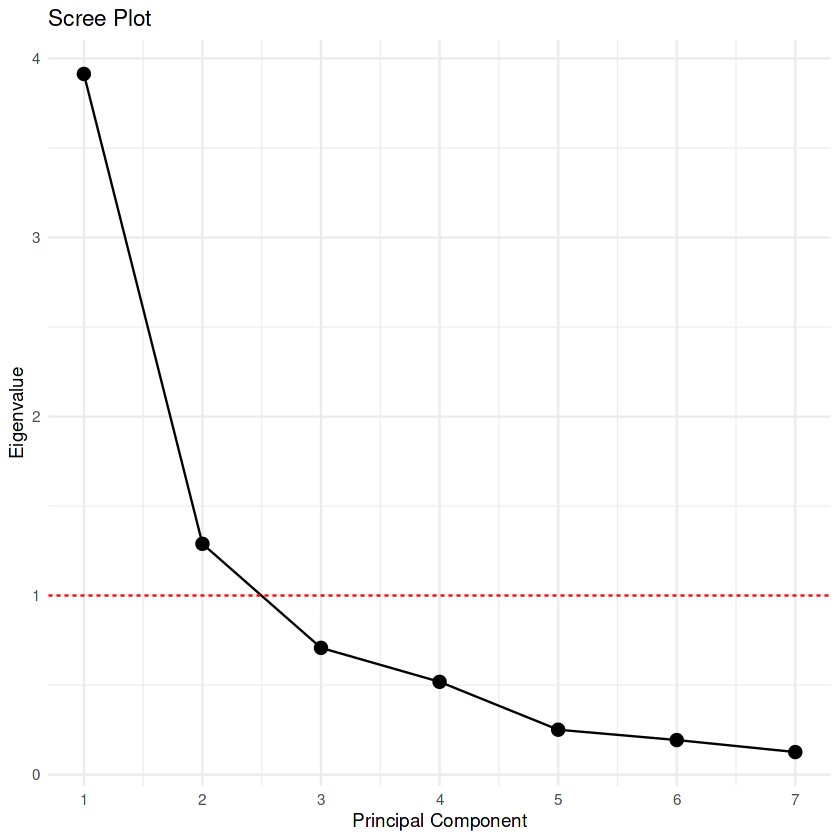

In [12]:
scree <- ggplot(var_table, aes(x = 1:7, y = Eigenvalue)) +
  geom_line() + geom_point(size = 3) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "red") +
  scale_x_continuous(breaks = 1:7) +
  labs(title = "Scree Plot", x = "Principal Component", y = "Eigenvalue") +
  theme_minimal()
print(scree)
ggsave("scree_plot.png", scree, width = 6, height = 4, dpi = 300)

### C2

The elbow is at PC3. After the sharp drop through PC2, the curve bends and flattens, with eigenvalues of 0.708, 0.518 and then below 0.26. The components before the elbow, PC1 and PC2, are the ones that carry substantial information, so the scree plot suggests retaining 2 components.

### C3

In [13]:
cat("Components with eigenvalue > 1:", sum(eig > 1), "\n")

Components with eigenvalue > 1: 2 


Only PC1 (3.914) and PC2 (1.289) have eigenvalues greater than 1, so the Kaiser criterion also points to 2 components. PC3 (0.708) falls below 1, meaning it explains less variance than a single original standardized variable.

### C4

The scree plot has its elbow at PC3, the Kaiser criterion keeps two, and together PC1 and PC2 explain 74.3% of the total variance, a reasonable amount for reducing seven variables to two. PC1 and PC2 are also easy to interpret (Part D). Adding PC3 would raise the cumulative variance to 84.4%, but its eigenvalue is below 1 and it is dominated almost entirely by a single variable (Perceptions of corruption, -0.801), so it adds little new interpretable structure. Therefore 2 principal components are to be retained.

### C5

The scree plot is subjective, because the elbow can be hard to place. The Kaiser rule is an arbitrary cutoff and can keep too many or too few components. A cumulative-variance threshold (such as 70% or 80%) is also a judgment call. As the module notes, there is no single definitive answer, so the decision should combine explained variance, eigenvalue magnitudes, the scree plot and whether the retained components make sense in context.

# Part D – Interpretation of Principal Components

### D1

PC1 is a contrast between the four development and well-being indicators and the corruption perception, with the first group dominating. Ladder score (-0.464), Logged GDP per capita (-0.459), Healthy life expectancy (-0.453) and Social support (-0.433) load strongly and in the same direction, Freedom to make life choices loads moderately (-0.341), and Perceptions of corruption loads in the opposite direction (0.252). Generosity is negligible (0.042). Countries with high scores on PC1 (in the sign direction of the loadings) therefore tend to be wealthy, healthy, socially supported, free, and happier, with lower perceived corruption. Because PCA signs are arbitrary, multiplying PC1 by -1 gives the more intuitive reading, where a higher score means better overall conditions.

### D2

PC2 is driven mainly by Generosity (0.753), followed by Perceptions of corruption (-0.460) and Freedom to make life choices (0.365). Economic and health variables have small negative coefficients (GDP -0.197, Social support -0.163, Healthy life expectancy -0.146), and Ladder score is almost zero (0.040). So PC2 separates countries that are generous and report more freedom, while perceiving less corruption, from those that are less generous and perceive more corruption. This is a dimension of civic and social character that is largely independent of wealth and health.

### D3

Overall Socio-Economic Development and Well-Being

Its largest loadings are on income (Logged GDP), health (Healthy life expectancy), social connection (Social support) and subjective well-being (Ladder score), with freedom and low perceived corruption contributing in the same direction.

### D4

In [15]:
load12 <- sweep(pca$rotation[, 1:2], 2, pca$sdev[1:2], "*")
print(round(rowSums(load12^2), 3))

                Ladder score        Logged GDP per capita 
                       0.845                        0.875 
              Social support      Healthy life expectancy 
                       0.766                        0.831 
Freedom to make life choices                   Generosity 
                       0.626                        0.739 
   Perceptions of corruption 
                       0.522 


The two retained components summarize all 7 original variables in just 2 dimensions, retaining 74.3% of the total variance. PC1 effectively represents the group of four variables (Ladder score, GDP, Social support, Healthy life expectancy) with Freedom partly included, and PC2 mainly represents Generosity (together with part of Corruption and Freedom). The code above gives how much of each variable’s variance the two components capture. From my own calculation with the rounded loadings, I expect the four main variables and Generosity to be well represented, while Freedom and especially Perceptions of corruption are represented less fully. Check this against your output before including it.

### D5

PCA shows that the seven well-being variables can be reduced to two main dimensions without losing much information. The first dimension (55.9% of variance) is a general development and well-being factor that combines income, health, social support, life evaluation and, to a lesser degree, freedom and low corruption perceptions. The second dimension (18.4%) captures civic and social character, mainly generosity, in contrast with perceived corruption, and is largely independent of wealth. So cross-country well-being is mostly one broad dimension of material and social conditions, with a second smaller dimension that reflects how generous and trusting a society is rather than how rich it is. The two criteria used, the scree plot and Kaiser rule, support retaining these two components.